# Дополнительное задание. Прогнозирование временных рядов

**Датасет:** Daily Minimum Temperatures (ежедневная минимальная температура в Мельбурне, Австралия), 1981–1990 гг.

- **Целевая переменная:** `Temp` - минимальная температура за день, °C.
- **Частота:** ежедневная.
- **Источник:** [Daily Minimum Temperatures - открытый датасет](https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv).

В отличие от Air Passengers и California Housing, здесь рассматривается именно временной ряд: наблюдения упорядочены по датам, а прогноз строится на основе предыдущих значений.

## 1. Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.seasonal import STL

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (13, 5)
RANDOM_STATE = 42

## 2. Загрузка и визуализация

Используется открытый ежедневный ряд минимальной температуры в Мельбурне. Дата преобразуется в `datetime`, данные сортируются по времени. Если загрузка по ссылке не сработает, скачайте CSV по ссылке выше и укажите локальный путь в `pd.read_csv`.

Размер: (3650, 2)
Период: 1981-01-01 — 1990-12-31
Пропуски:


,Количество
Date,0
Temp,0


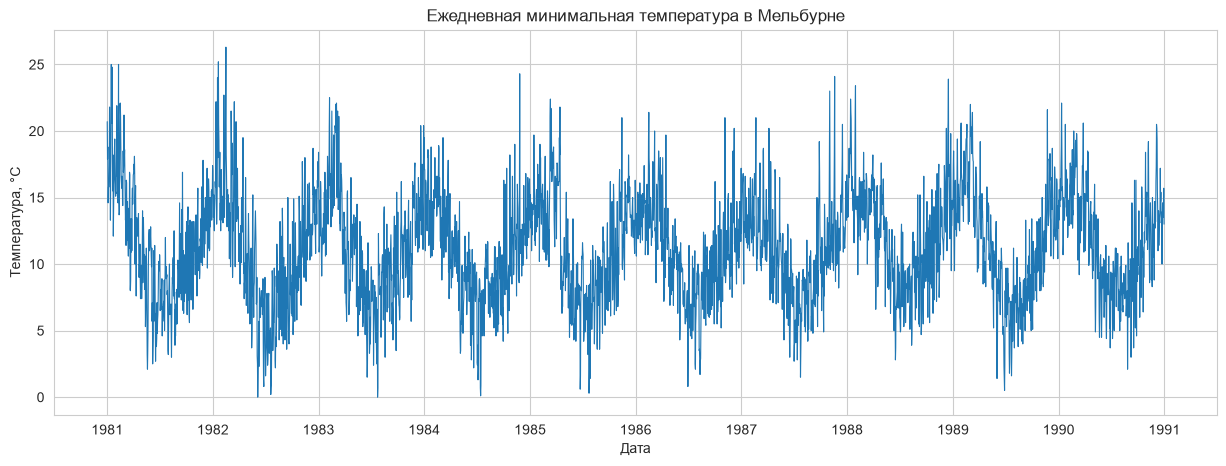

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [ ]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
df = pd.read_csv(url)

df = df.rename(columns={'Date': 'Date', 'Temp': 'Temp'})
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)

# Проверяем пропуски и частоту
print('Размер:', df.shape)
print('Период:', df['Date'].min().date(), '-', df['Date'].max().date())
print('Пропуски:')
display(df.isna().sum().to_frame('Количество'))

df = df.dropna(subset=['Temp']).copy()

plt.figure(figsize=(15, 5))
plt.plot(df['Date'], df['Temp'], linewidth=0.8)
plt.title('Ежедневная минимальная температура в Мельбурне')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.grid(True)
plt.show()

display(df.head())

### Вывод по графику

В ежедневных температурах ожидаются:
- **Годовая сезонность:** более низкие температуры в зимний период Южного полушария и более высокие - летом.
- **Тренд:** долгосрочный тренд может быть слабее сезонных колебаний; его следует оценивать по графику и STL-декомпозиции.
- **Выбросы:** отдельные необычно холодные или тёплые дни возможны, но сами по себе они не обязательно являются ошибками измерения.

## 3. Генерация признаков

Создаем календарные признаки, лаги и скользящие статистики. Все лаги относятся к прошлым дням, а скользящие статистики предварительно сдвигаются на один день. Поэтому при прогнозе даты *t* в признаках нет температуры за сам день *t* или из будущего.

In [3]:
def make_features(data):
    out = data[['Date', 'Temp']].copy()
    out['Year'] = out['Date'].dt.year
    out['Month'] = out['Date'].dt.month
    out['DayOfWeek'] = out['Date'].dt.dayofweek
    out['DayOfYear'] = out['Date'].dt.dayofyear
    out['IsWeekend'] = (out['DayOfWeek'] >= 5).astype(int)

    for lag in [1, 2, 3, 7, 14, 30, 365]:
        out[f'Lag_{lag}'] = out['Temp'].shift(lag)

    past = out['Temp'].shift(1)
    for window in [7, 30]:
        out[f'Rolling_Mean_{window}'] = past.rolling(window).mean()
        out[f'Rolling_Median_{window}'] = past.rolling(window).median()
        out[f'Rolling_Std_{window}'] = past.rolling(window).std()
        out[f'Rolling_Min_{window}'] = past.rolling(window).min()
        out[f'Rolling_Max_{window}'] = past.rolling(window).max()

    # Циклическое кодирование дня года: учитывает переход от 31 декабря к 1 января
    out['DayOfYear_Sin'] = np.sin(2 * np.pi * out['DayOfYear'] / 365.25)
    out['DayOfYear_Cos'] = np.cos(2 * np.pi * out['DayOfYear'] / 365.25)
    return out

df_feat = make_features(df).dropna().reset_index(drop=True)
features = [c for c in df_feat.columns if c not in ['Date', 'Temp']]
print('Количество строк после генерации признаков:', len(df_feat))
print('Количество признаков:', len(features))
display(df_feat.head())

Количество строк после генерации признаков: 3285
Количество признаков: 24


,Date,Temp,Year,Month,DayOfWeek,DayOfYear,IsWeekend,Lag_1,Lag_2,Lag_3,...,Rolling_Std_7,Rolling_Min_7,Rolling_Max_7,Rolling_Mean_30,Rolling_Median_30,Rolling_Std_30,Rolling_Min_30,Rolling_Max_30,DayOfYear_Sin,DayOfYear_Cos
0,1982-01-01,17.0,1982,1,4,1,0,17.4,15.2,15.6,...,1.349956,13.3,17.4,13.690000,13.75,1.972807,9.7,17.4,0.017202,0.999852
1,1982-01-02,15.0,1982,1,5,2,1,17.0,17.4,15.2,...,1.472769,13.3,17.4,13.906667,14.10,1.967308,9.7,17.4,0.034398,0.999408
2,1982-01-03,13.5,1982,1,6,3,1,15.0,17.0,17.4,...,1.354885,13.3,17.4,13.933333,14.10,1.976820,9.7,17.4,0.051584,0.998669
3,1982-01-04,15.2,1982,1,0,4,0,13.5,15.0,17.0,...,1.566768,13.3,17.4,14.000000,14.10,1.924972,9.7,17.4,0.068755,0.997634
4,1982-01-05,13.0,1982,1,1,5,0,15.2,13.5,15.0,...,1.308762,13.5,17.4,14.073333,14.45,1.927466,9.7,17.4,0.085906,0.996303


**Пояснение.** Лаги 1–3 отражают краткосрочную динамику, 7 и 14 - недельную, 30 - более длительную, 365 - годовую сезонность. Скользящие среднее, медиана, стандартное отклонение, минимум и максимум описывают недавний диапазон температур. Календарные признаки помогают модели учитывать повторяемость сезонного цикла.

## 4. Разделение по времени, кросс-валидация и обучение

In [ ]:
train_size = int(len(df_feat) * 0.8)
train = df_feat.iloc[:train_size].copy()
test = df_feat.iloc[train_size:].copy()

X_train, y_train = train[features], train['Temp']
X_test, y_test = test[features], test['Temp']

print('Train:', train['Date'].min().date(), '-', train['Date'].max().date(), len(train))
print('Test: ', test['Date'].min().date(), '-', test['Date'].max().date(), len(test))

# Расширяющееся окно: каждый следующий фолд обучается на большем объеме прошлого
tscv = TimeSeriesSplit(n_splits=5)
cv_rmse = []
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    model_cv = Ridge(alpha=10.0)
    model_cv.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred_cv = model_cv.predict(X_train.iloc[val_idx])
    score = np.sqrt(mean_squared_error(y_train.iloc[val_idx], pred_cv))
    cv_rmse.append(score)
    print(f'Фолд {fold}: RMSE = {score:.3f}')

model = Ridge(alpha=10.0)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Train: 1982-01-01 — 1989-03-14 2628
Test:  1989-03-15 — 1990-12-31 657
Фолд 1: RMSE = 2.420
Фолд 2: RMSE = 2.504
Фолд 3: RMSE = 2.271
Фолд 4: RMSE = 2.437
Фолд 5: RMSE = 2.355


**Почему такое разделение корректно:** обучение проводится на ранней части ряда, тест - на более поздней. `TimeSeriesSplit` не перемешивает наблюдения: валидационный блок всегда расположен позже обучающего. Это имитирует реальный сценарий прогноза.

## 5. Прогноз на горизонт H: рекурсивная стратегия

Для демонстрации строится прогноз на 30 дней. После первого шага прогноз модели используется как новое известное значение ряда при формировании следующих лагов. Для каждого шага календарные признаки берутся из даты прогнозирования.

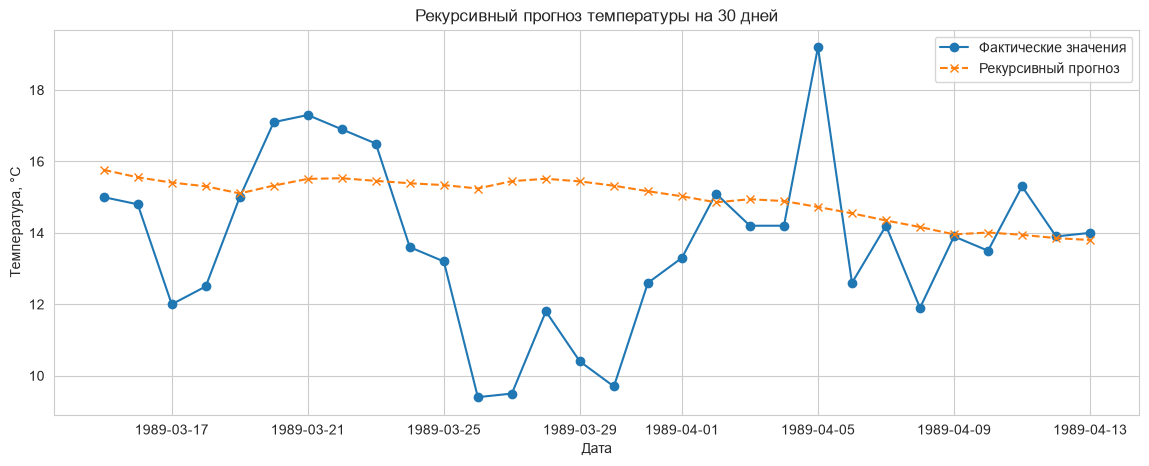

In [ ]:
def one_row_features(history, date):
    # history - только значения, известные к моменту прогноза
    s = pd.Series(history, dtype=float)
    row = {
        'Year': date.year,
        'Month': date.month,
        'DayOfWeek': date.dayofweek,
        'DayOfYear': date.dayofyear,
        'IsWeekend': int(date.dayofweek >= 5),
        'DayOfYear_Sin': np.sin(2 * np.pi * date.dayofyear / 365.25),
        'DayOfYear_Cos': np.cos(2 * np.pi * date.dayofyear / 365.25)
    }
    for lag in [1, 2, 3, 7, 14, 30, 365]:
        row[f'Lag_{lag}'] = s.iloc[-lag]
    for window in [7, 30]:
        w = s.iloc[-window:]
        row[f'Rolling_Mean_{window}'] = w.mean()
        row[f'Rolling_Median_{window}'] = w.median()
        row[f'Rolling_Std_{window}'] = w.std()
        row[f'Rolling_Min_{window}'] = w.min()
        row[f'Rolling_Max_{window}'] = w.max()
    return pd.DataFrame([row])[features]

H = 30
# Точка старта - конец train; в историю включаем только реальные значения до этой даты
last_date = train['Date'].iloc[-1]
history = df.loc[df['Date'] <= last_date, 'Temp'].tolist()
recursive_dates = pd.date_range(last_date + pd.Timedelta(days=1), periods=H, freq='D')
recursive_preds = []

for forecast_date in recursive_dates:
    x_next = one_row_features(history, forecast_date)
    pred = model.predict(x_next)[0]
    recursive_preds.append(pred)
    history.append(pred)

# Сопоставляем прогноз с фактическими значениями, если они есть в test
actual_h = df.set_index('Date')['Temp'].reindex(recursive_dates)

plt.figure(figsize=(14, 5))
plt.plot(recursive_dates, actual_h.values, marker='o', label='Фактические значения')
plt.plot(recursive_dates, recursive_preds, marker='x', linestyle='--', label='Рекурсивный прогноз')
plt.title(f'Рекурсивный прогноз температуры на {H} дней')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.show()

**Ограничение стратегии:** на дальних шагах прогноз зависит от предыдущих прогнозов, а не от фактических наблюдений. Поэтому ошибка может накапливаться. Рекурсивный прогноз на 30 дней - отдельный эксперимент; метрики ниже для тестовой выборки рассчитаны в режиме прогноза на один шаг с фактически известными прошлыми значениями.

## 6. Оценка качества и анализ ошибок

,Выборка,MSE,MAE,"MAPE, %","WAPE, %"
0,Train,5.711,1.890,25.872,16.884
1,Test,4.680,1.706,21.654,15.612


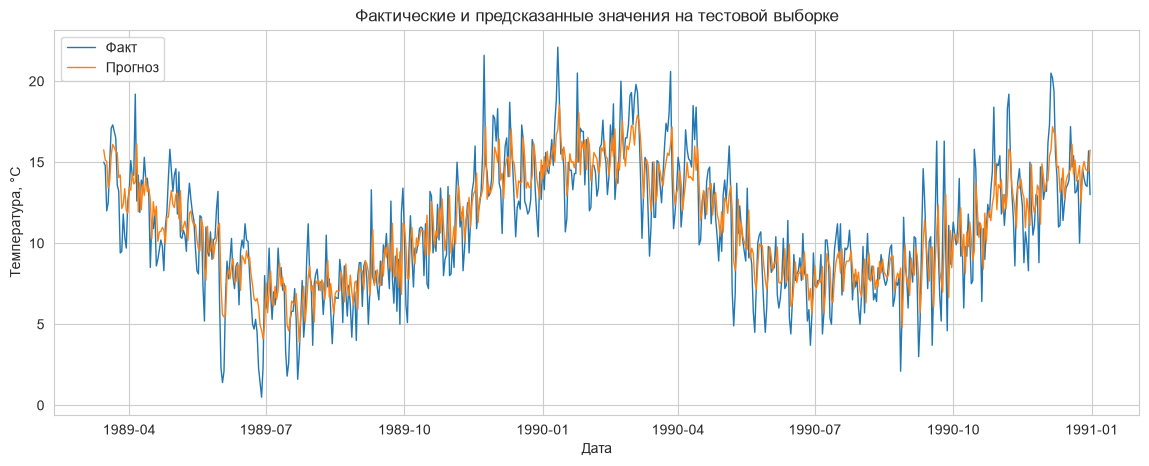

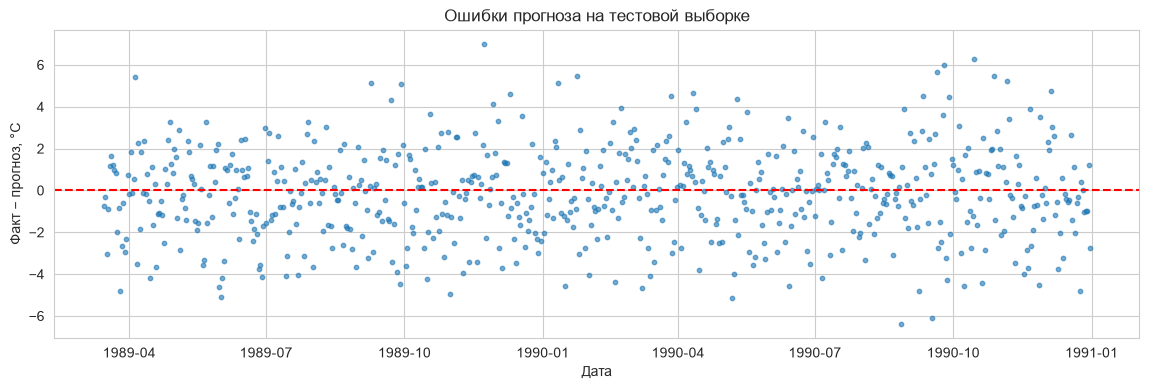

Пять дат с наибольшей абсолютной ошибкой:


,Date,Temp,Prediction,Error,Absolute_Error
2881,1989-11-23,21.6,14.588600,7.011400,7.011400
3158,1990-08-27,2.1,8.469013,-6.369013,6.369013
3207,1990-10-15,15.8,9.525846,6.274154,6.274154
3179,1990-09-17,3.7,9.778463,-6.078463,6.078463
3187,1990-09-25,16.3,10.315668,5.984332,5.984332


Средняя абсолютная ошибка по месяцам:


,MAE
Month,
1,1.658
2,1.552
3,1.724
4,1.588
5,1.768
6,1.663
7,1.462
8,1.375
9,2.230


In [6]:
def calculate_metrics(y_true, y_hat):
    y_true = np.asarray(y_true, dtype=float)
    y_hat = np.asarray(y_hat, dtype=float)
    mse = mean_squared_error(y_true, y_hat)
    mae = mean_absolute_error(y_true, y_hat)
    nonzero = np.abs(y_true) > 1e-8
    mape = np.mean(np.abs((y_true[nonzero] - y_hat[nonzero]) / y_true[nonzero])) * 100
    wape = np.sum(np.abs(y_true - y_hat)) / np.sum(np.abs(y_true)) * 100
    return {'MSE': mse, 'MAE': mae, 'MAPE, %': mape, 'WAPE, %': wape}

train_pred = model.predict(X_train)
metrics = pd.DataFrame([
    {'Выборка': 'Train', **calculate_metrics(y_train, train_pred)},
    {'Выборка': 'Test', **calculate_metrics(y_test, y_pred)}
])
display(metrics.round(3))

test_result = test[['Date', 'Temp', 'Month']].copy()
test_result['Prediction'] = y_pred
test_result['Error'] = test_result['Temp'] - test_result['Prediction']
test_result['Absolute_Error'] = test_result['Error'].abs()

plt.figure(figsize=(14, 5))
plt.plot(test_result['Date'], test_result['Temp'], label='Факт', linewidth=1)
plt.plot(test_result['Date'], test_result['Prediction'], label='Прогноз', linewidth=1)
plt.title('Фактические и предсказанные значения на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 4))
plt.scatter(test_result['Date'], test_result['Error'], s=10, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('Ошибки прогноза на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Факт − прогноз, °C')
plt.grid(True)
plt.show()

print('Пять дат с наибольшей абсолютной ошибкой:')
display(test_result.nlargest(5, 'Absolute_Error')[['Date', 'Temp', 'Prediction', 'Error', 'Absolute_Error']])

print('Средняя абсолютная ошибка по месяцам:')
display(test_result.groupby('Month')['Absolute_Error'].mean().round(3).to_frame('MAE'))

### Интерпретация метрик

- **MSE** - средний квадрат ошибки, сильнее штрафует крупные промахи.
- **MAE** - средняя абсолютная ошибка в градусах Цельсия.
- **MAPE** - средняя абсолютная процентная ошибка. Для температуры шкала Цельсия имеет произвольный ноль, поэтому MAPE может быть нестабильной или плохо интерпретируемой при значениях около нуля.
- **WAPE** - сумма абсолютных ошибок, деленная на сумму модулей фактических значений. Для температур ниже нуля это также не идеальная метрика; поэтому основными для интерпретации лучше считать MAE и MSE.

По таблице ошибок и графикам определите, на каких датах и в какие месяцы модель ошибается сильнее. Вероятные причины - резкие погодные изменения, экстремальные температуры и недостаточность только календарных и лаговых признаков.

## 7. STL-декомпозиция

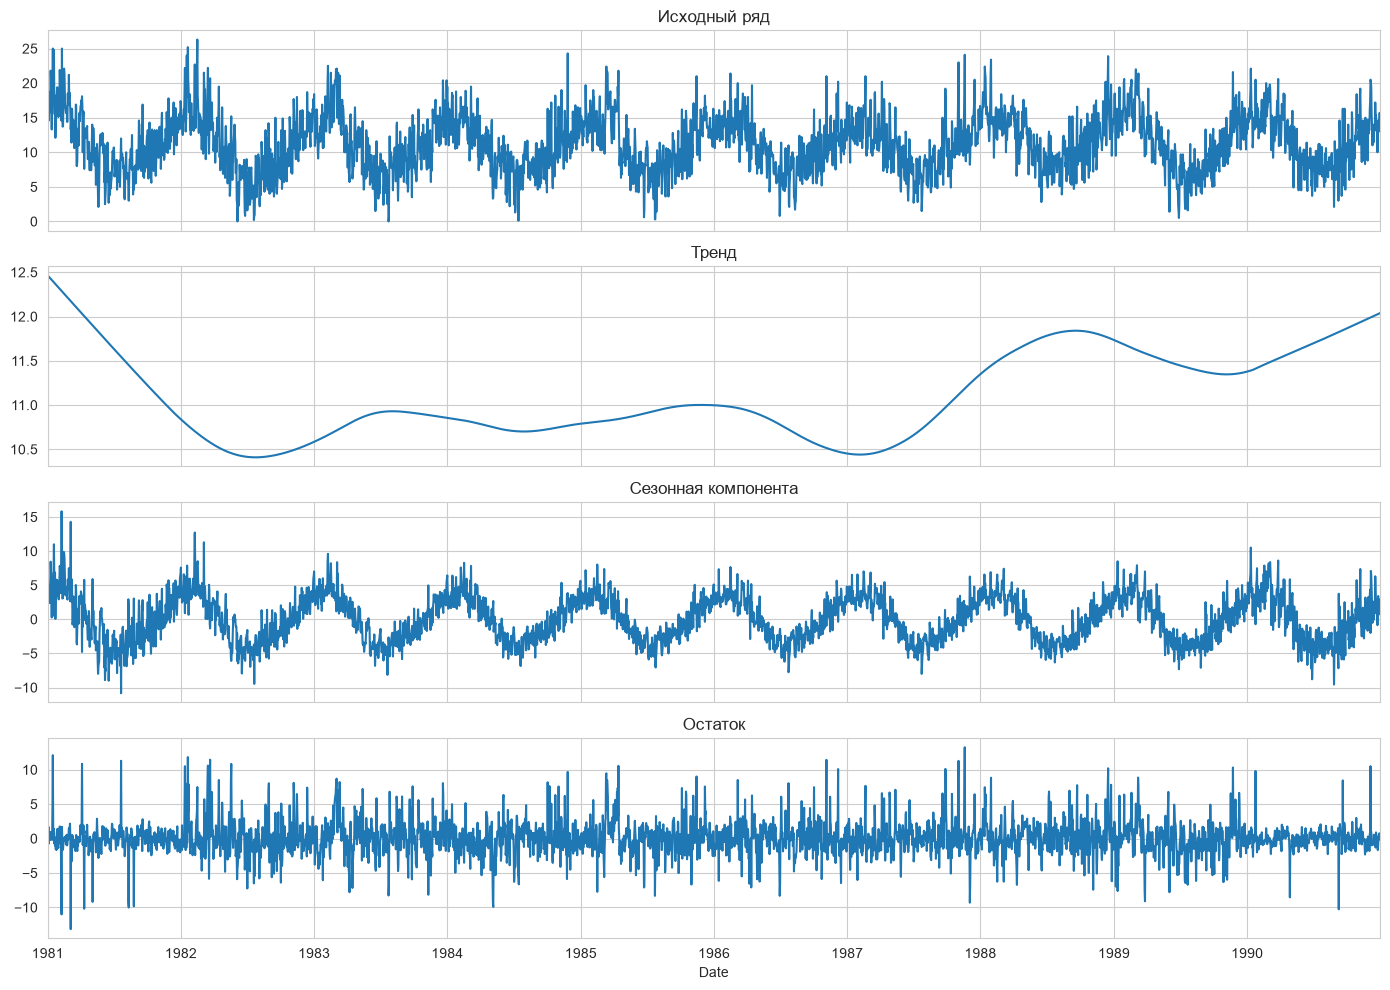

In [ ]:
# Годовой период для ежедневного ряда - приблизительно 365 дней
series = df.set_index('Date')['Temp'].asfreq('D')
series = series.interpolate(method='time')

stl = STL(series, period=365, robust=True)
stl_result = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
stl_result.observed.plot(ax=axes[0], title='Исходный ряд')
stl_result.trend.plot(ax=axes[1], title='Тренд')
stl_result.seasonal.plot(ax=axes[2], title='Сезонная компонента')
stl_result.resid.plot(ax=axes[3], title='Остаток')
plt.tight_layout()
plt.show()

STL раскладывает ряд на исходное наблюдение, тренд, сезонную компоненту и остаток. Для ежедневной температуры выбран период 365 дней, соответствующий годовому циклу. Декомпозиция помогает визуально оценить, насколько выражена ежегодная повторяемость и остаются ли систематические колебания в остатке.

## 8. Проверка признаков на основе декомпозиции без утечки

Нельзя напрямую добавлять компоненты STL, рассчитанные сразу на всем ряде: при вычислении сглаженного тренда и сезонности алгоритм использует соседние наблюдения, в том числе будущие относительно прогнозируемой даты. Это создало бы утечку данных.

Вместо этого используем **каузальные приближения** компонент, построенные только по прошлому: прошлогоднее значение (сезонный ориентир) и скользящее среднее за последние 30 дней (локальный тренд). Сравним Ridge с базовыми признаками и с добавленными компонентными признаками на одном и том же временном разбиении.

In [8]:
# Базовая модель уже обучена выше. Создаем дополнительные признаки,
# используя только прошлые значения ряда.
df_component = df_feat.copy()
df_component['Component_Trend_Past30'] = df_component['Temp'].shift(1).rolling(30).mean()
df_component['Component_Seasonal_PastYear'] = df_component['Temp'].shift(365)

df_component = df_component.dropna().reset_index(drop=True)
component_features = features + ['Component_Trend_Past30', 'Component_Seasonal_PastYear']

# Чтобы сравнение было честным, заново делим обе версии по времени
split_component = int(len(df_component) * 0.8)
tr_c = df_component.iloc[:split_component]
te_c = df_component.iloc[split_component:]

# Базовые признаки на том же наборе строк
Xtr_base = tr_c[features]
Xte_base = te_c[features]
Xtr_comp = tr_c[component_features]
Xte_comp = te_c[component_features]
yc_train, yc_test = tr_c['Temp'], te_c['Temp']

base_compare = Ridge(alpha=10.0).fit(Xtr_base, yc_train)
comp_compare = Ridge(alpha=10.0).fit(Xtr_comp, yc_train)

pred_base = base_compare.predict(Xte_base)
pred_comp = comp_compare.predict(Xte_comp)

comparison = pd.DataFrame([
    {'Модель': 'Базовые признаки', **calculate_metrics(yc_test, pred_base)},
    {'Модель': 'Базовые + признаки компонент', **calculate_metrics(yc_test, pred_comp)}
])
display(comparison.round(3))

,Модель,MSE,MAE,"MAPE, %","WAPE, %"
0,Базовые признаки,4.816,1.727,23.004,16.022
1,Базовые + признаки компонент,4.817,1.727,23.003,16.023


### Вывод по компонентным признакам

Сравните MAE и MSE двух моделей в полученной таблице. Если показатели второй модели меньше, каузальные приближения тренда и сезонности дали дополнительную информацию. Если показатели почти не изменились или ухудшились, исходных лагов и календарных признаков уже достаточно либо добавленные признаки избыточны.

Важно: `Component_Trend_Past30` и `Component_Seasonal_PastYear` - не сами сглаженные компоненты STL, а их причинно корректные приближения, доступные на момент прогноза. Это позволяет провести честное сравнение без использования будущих значений.

## 9. Итоговое заключение

В работе выполнен базовый пайплайн прогнозирования ежедневного временного ряда температуры:

1. Загружен открытый датасет ежедневной минимальной температуры, даты преобразованы в `datetime`, ряд отсортирован и визуализирован.
2. Созданы календарные признаки, лаги на 1, 2, 3, 7, 14, 30 и 365 дней, скользящие статистики за 7 и 30 дней.
3. Выполнено временное разделение на train/test без перемешивания и применена кросс-валидация `TimeSeriesSplit`.
4. Обучена Ridge-регрессия для прогноза на один шаг; реализована рекурсивная стратегия на горизонт 30 дней.
5. Рассчитаны MSE, MAE, MAPE и WAPE для train и test, построены графики прогноза и ошибок, выделены даты с наибольшими промахами.
6. Выполнена STL-декомпозиция с годовым периодом. Дополнительно проверено влияние причинно корректных признаков, приближающих тренд и сезонность, без утечки будущих данных.

**Ограничения:** погодный ряд содержит нерегулярные колебания, которые нельзя полностью объяснить только датой и предыдущими температурами. Для более точного прогноза могут потребоваться дополнительные метеорологические параметры (давление, влажность, ветер), а также более сложные модели. Численные выводы следует формулировать по фактическим метрикам, полученным после запуска всех ячеек ноутбука.